# 🧪 Notebook 3 — RAG Evaluation with RAGAS
## TeleCopilot-AI end-to-end answer quality

This notebook runs the **production pipeline** (Cohere + BM25 query embedding → Qdrant hybrid search with RRF →
Cohere Rerank v3.5 → Gemini JSON answer) on a fixed set of CSR questions, then scores it with **RAGAS**.

- **Test set:** `experiments/rag_eval/eval_questions.json` — 13 questions (10 English, 3 Arabic) across 8 intents.
  Every reference answer is taken word-for-word from the human-verified ground truth in `data/ground_truth/`.
- **Vector DB:** an embedded Qdrant instance (`QdrantClient(":memory:")`), so the real hybrid RRF search is used
  without a Qdrant server.
- **Judge:** Gemini (via Google's OpenAI-compatible endpoint) with Cohere `embed-multilingual-v3.0` embeddings.

| Metric | What it checks |
|---|---|
| Faithfulness | Is every claim in the answer supported by the retrieved context? (hallucination check) |
| Answer relevancy | Does the answer address the question? |
| Context precision | Are the relevant chunks ranked at the top? |
| Context recall | Does the retrieved context contain everything needed for the reference answer? |
| Factual correctness | Does the answer agree with the reference answer? |


## ⚙️ Section 1 — Setup

In [1]:
import os, sys, json, time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()
os.chdir(ROOT)
for p in [str(ROOT / "src"), str(ROOT)]:
    if p not in sys.path:
        sys.path.insert(0, p)

from dotenv import load_dotenv
load_dotenv(ROOT / ".env")
for k in ["COHERE_API_KEY", "GEMINI_API_KEY"]:
    print(f"{k} set: {bool(os.getenv(k))}")   # never print the key itself

REPORTS = ROOT / "experiments" / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)
EVAL_SET = json.loads((ROOT / "experiments" / "rag_eval" / "eval_questions.json").read_text(encoding="utf-8"))
print(f"Loaded {len(EVAL_SET)} evaluation questions")

COHERE_API_KEY set: True
GEMINI_API_KEY set: True
Loaded 13 evaluation questions


## 🗄️ Section 2 — Build the index (embedded Qdrant, real hybrid search)

In [2]:
from qdrant_client import QdrantClient
from core.singletons import SingletonsManager
from config.settings import get_settings
from repositories.qdrant_repository import QdrantVectorRepository
from services.cohere_service import CohereService
from services.gemini_service import GeminiService
from services.ingestion_service import IngestionService
from services.agent_assist_service import AgentAssistService

settings = get_settings()
SingletonsManager._qdrant_client = QdrantClient(":memory:")   # embedded Qdrant, no server needed

repo = QdrantVectorRepository()
assert repo._is_live, "Qdrant should be live (embedded mode)"
cohere_svc, gemini_svc = CohereService(), GeminiService()

t0 = time.time()
ingest_results = IngestionService(repo, cohere_svc).ingest_all_default_policies()
print(f"Indexed {len(ingest_results)} sources, {repo.count()} chunks in {time.time() - t0:.0f}s")

service = AgentAssistService(vector_repo=repo, cohere_service=cohere_svc, gemini_service=gemini_svc)
print("Models:", settings.DENSE_EMBEDDING_MODEL, "|", settings.RERANK_MODEL, "|", settings.LLM_MODEL)

2026-10-14 12:17:54.092 | INFO     | repositories.qdrant_repository:initialize_collection:39 - Creating Qdrant collection 'telecom_customer_policies' with Dense (Cohere) + Sparse (BM25) vector indexes...


2026-10-14 12:17:54.105 | INFO     | repositories.qdrant_repository:initialize_collection:57 - Connected to Qdrant collection: telecom_customer_policies (Dense + Sparse Hybrid ready)


2026-10-14 12:17:55.694 | INFO     | core.singletons:get_cohere_client:41 - Cohere Client initialized successfully.


2026-10-14 12:17:58.816 | INFO     | core.singletons:get_gemini_client:57 - Google Gemini Client initialized with model: gemini-3.1-flash-lite-preview


2026-10-14 12:17:58.831 | INFO     | services.ingestion_service:ingest_all_default_policies:123 - Discovered 10 local policy files in <local-path> ['<local-path>', '<local-path>', '<local-path>', '<local-path>', '<local-path>', '<local-path>', '<local-path>', '<local-path>', '<local-path>', '<local-path>']


...

2026-10-14 12:19:16.918 | INFO     | ingestion.extractors.web_scraper_extractor:scrape_url_in_memory:38 - Fetched https://www.te.eg/web/guest/personal/services/international-roaming (298586 bytes)


2026-10-14 12:19:16.985 | INFO     | ingestion.chunkers.policy_chunkers:chunk:371 - LangChain WebScrapedPolicyChunker produced 1 chunks.


2026-10-14 12:19:17.351 | INFO     | repositories.qdrant_repository:upsert_chunks:107 - Upserted 1 chunks with Dense + Sparse vectors into Qdrant (telecom_customer_policies).


2026-10-14 12:19:17.356 | INFO     | services.ingestion_service:ingest_url:62 - Successfully scraped & indexed 1 chunks from https://www.te.eg/web/guest/personal/services/international-roaming into Qdrant.


Indexed 14 sources, 655 chunks in 79s
Models: embed-multilingual-v3.0 | rerank-v3.5 | gemini-3.1-flash-lite-preview


## 🤖 Section 3 — Run the pipeline on every question

In [3]:
def run_pipeline(question: str) -> dict:
    """Same steps as AgentAssistService.solve_customer_problem, but keeps the full retrieved contexts."""
    t = time.time()
    dense, sparse = service._embed_query(question)
    candidates = service._hybrid_search(question, dense, sparse, None, None)
    contexts = service._rerank(question, candidates)
    solution = gemini_svc.generate_agent_solution(question, contexts)
    answer = solution.get("suggested_customer_reply", "")
    steps = solution.get("actionable_agent_steps") or []
    if steps:
        answer += "\n\nAgent steps:\n" + "\n".join(f"- {s}" for s in steps)
    return {
        "response": answer.strip(),
        "retrieved_contexts": [c["content"] for c in contexts],
        "retrieved_sources": [os.path.basename(str(c["source"]).replace("\\", "/")) for c in contexts],
        "top_intent": contexts[0]["intent_category"] if contexts else None,
        "latency_s": round(time.time() - t, 2),
    }

rows = []
for item in EVAL_SET:
    out = run_pipeline(item["question"])
    rows.append({**item, **out})
    hit = item["source"] in out["retrieved_sources"]
    print(f"{item['id']} | {out['latency_s']:>5}s | source retrieved: {'✅' if hit else '❌'} | {item['question'][:60]}")
    time.sleep(1)   # stay under free-tier rate limits

2026-10-14 12:19:21.249 | INFO     | services.gemini_service:generate_agent_solution:109 - Gemini batch solution generated for query: 'A customer says their phone was just stolen. What must the a...'


Q01 |  3.87s | source retrieved: ✅ | A customer says their phone was just stolen. What must the a


2026-10-14 12:19:27.385 | INFO     | services.gemini_service:generate_agent_solution:109 - Gemini batch solution generated for query: 'How much does a replacement SIM cost for a lost or stolen li...'


Q02 |  5.14s | source retrieved: ✅ | How much does a replacement SIM cost for a lost or stolen li


2026-10-14 12:19:32.516 | INFO     | services.gemini_service:generate_agent_solution:109 - Gemini batch solution generated for query: 'A customer's SIM card burned out two months after it was iss...'


...

Q11 |  8.62s | source retrieved: ✅ | Is there a limit on data roaming charges if the customer has


2026-10-14 12:20:23.769 | INFO     | services.gemini_service:generate_agent_solution:109 - Gemini batch solution generated for query: 'شركة لديها خط ربط مؤسسي كانت نسبة التشغيل الشهرية له 99.2%. ...'


Q12 |  9.58s | source retrieved: ✅ | شركة لديها خط ربط مؤسسي كانت نسبة التشغيل الشهرية له 99.2%. 


2026-10-14 12:20:28.020 | INFO     | services.gemini_service:generate_agent_solution:109 - Gemini batch solution generated for query: 'After a SIM replacement, why is the customer not receiving b...'


Q13 |  3.25s | source retrieved: ✅ | After a SIM replacement, why is the customer not receiving b


### Retrieval hit rate (no LLM judge needed)
Did the reranked top 3 include the document the reference answer comes from?

In [4]:
import pandas as pd
df = pd.DataFrame(rows)
df["source_hit"] = [r["source"] in r["retrieved_sources"] for r in rows]
df["intent_match"] = df["top_intent"] == df["intent"]
print(f"Source hit rate @3 : {df['source_hit'].mean():.0%}")
print(f"Intent accuracy    : {df['intent_match'].mean():.0%}")
print(f"Median latency     : {df['latency_s'].median():.1f}s")
df[["id", "language", "intent", "top_intent", "source_hit", "latency_s"]]

Source hit rate @3 : 100%
Intent accuracy    : 100%
Median latency     : 3.9s


,id,language,intent,top_intent,source_hit,latency_s
0,Q01,en,SIM_MANAGEMENT,SIM_MANAGEMENT,True,3.87
1,Q02,en,SIM_MANAGEMENT,SIM_MANAGEMENT,True,5.14
2,Q03,en,SIM_MANAGEMENT,SIM_MANAGEMENT,True,4.13
3,Q04,en,SIM_MANAGEMENT,SIM_MANAGEMENT,True,2.80
4,Q05,en,BILLING_AND_PAYMENTS,BILLING_AND_PAYMENTS,True,3.21
5,Q06,en,BILLING_AND_PAYMENTS,BILLING_AND_PAYMENTS,True,3.12
6,Q07,en,BILLING_AND_PAYMENTS,BILLING_AND_PAYMENTS,True,3.21
7,Q08,en,BROADBAND_INSTALLATION,BROADBAND_INSTALLATION,True,3.30
8,Q09,ar,NETWORK_TECHNICAL_SUPPORT,NETWORK_TECHNICAL_SUPPORT,True,3.90
9,Q10,en,ROAMING_AND_INTERNATIONAL,ROAMING_AND_INTERNATIONAL,True,4.50


## 📏 Section 4 — RAGAS scoring

In [5]:
from ragas import evaluate, EvaluationDataset, RunConfig
from ragas.llms import LangchainLLMWrapper
from ragas.embeddings import LangchainEmbeddingsWrapper
from ragas.metrics import (Faithfulness, ResponseRelevancy, LLMContextPrecisionWithReference,
                           LLMContextRecall, FactualCorrectness)
from langchain_openai import ChatOpenAI
from langchain_cohere import CohereEmbeddings

judge_llm = LangchainLLMWrapper(ChatOpenAI(
    model=settings.LLM_MODEL,
    api_key=os.environ["GEMINI_API_KEY"],
    base_url="https://generativelanguage.googleapis.com/v1beta/openai/",
    temperature=0,
))
judge_emb = LangchainEmbeddingsWrapper(CohereEmbeddings(model="embed-multilingual-v3.0"))

dataset = EvaluationDataset.from_list([
    {"user_input": r["question"], "response": r["response"],
     "retrieved_contexts": r["retrieved_contexts"], "reference": r["reference"]}
    for r in rows
])
# strictness=1: Gemini's OpenAI-compatible endpoint does not support multiple candidates (n>1)
metrics = [Faithfulness(), ResponseRelevancy(strictness=1), LLMContextPrecisionWithReference(),
           LLMContextRecall(), FactualCorrectness(mode="recall")]

result = evaluate(dataset, metrics=metrics, llm=judge_llm, embeddings=judge_emb,
                  run_config=RunConfig(max_workers=2, timeout=240, max_retries=6), show_progress=True)
scores = result.to_pandas()
scores.insert(0, "id", df["id"])
scores.insert(1, "language", df["language"])
scores.insert(2, "intent", df["intent"])
scores

<local-path> DeprecationWarning: Importing Faithfulness from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import Faithfulness
  from ragas.metrics import (Faithfulness, ResponseRelevancy, LLMContextPrecisionWithReference,
<local-path> DeprecationWarning: Importing ResponseRelevancy from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import ResponseRelevancy
  from ragas.metrics import (Faithfulness, ResponseRelevancy, LLMContextPrecisionWithReference,
<local-path> DeprecationWarning: Importing LLMContextPrecisionWithReference from 'ragas.metrics' is deprecated and will be removed in v1.0. Please use 'ragas.metrics.collections' instead. Example: from ragas.metrics.collections import LLMContextPrecisionWithReference
  from ragas.metrics import (Faithfulness, ResponseRelevancy, LLMContextPr

<local-path> DeprecationWarning: LangchainLLMWrapper is deprecated and will be removed in a future version. Use llm_factory instead: from openai import OpenAI; from ragas.llms import llm_factory; llm = llm_factory('gpt-4o-mini', client=OpenAI(api_key='...'))
  judge_llm = LangchainLLMWrapper(ChatOpenAI(


<local-path> DeprecationWarning: LangchainEmbeddingsWrapper is deprecated and will be removed in a future version. Use the modern embedding providers instead: embedding_factory('openai', model='text-embedding-3-small', client=openai_client) or from ragas.embeddings import OpenAIEmbeddings, GoogleEmbeddings, HuggingFaceEmbeddings
  judge_emb = LangchainEmbeddingsWrapper(CohereEmbeddings(model="embed-multilingual-v3.0"))


Evaluating:   0%|          | 0/65 [00:00<?, ?it/s]

Evaluating:   2%|▏         | 1/65 [00:11<12:10, 11.42s/it]

...

Evaluating:  97%|█████████▋| 63/65 [10:12<00:19,  9.98s/it]

Evaluating:  98%|█████████▊| 64/65 [10:22<00:10, 10.15s/it]

Evaluating: 100%|██████████| 65/65 [10:34<00:00, 10.67s/it]

Evaluating: 100%|██████████| 65/65 [10:34<00:00,  9.76s/it]

,id,language,intent,user_input,retrieved_contexts,response,reference,faithfulness,answer_relevancy,llm_context_precision_with_reference,context_recall,factual_correctness(mode=recall)
0,Q01,en,SIM_MANAGEMENT,A customer says their phone was just stolen. W...,[[SOURCE: LOCAL_HTML] [INTENT: SIM_MANAGEMENT]...,I am very sorry to hear your phone was stolen....,The agent must immediately suspend outgoing ca...,0.800000,0.628802,0.0,0.333333,0.36
1,Q02,en,SIM_MANAGEMENT,How much does a replacement SIM cost for a los...,[[SOURCE: LOCAL_HTML] [INTENT: SIM_MANAGEMENT]...,I am sorry to hear that your SIM card was lost...,A lost or stolen SIM replacement costs 50 EGP....,0.750000,0.797795,1.0,1.000000,0.60
2,Q03,en,SIM_MANAGEMENT,A customer's SIM card burned out two months af...,[[SOURCE: LOCAL_HTML] [INTENT: SIM_MANAGEMENT]...,I am sorry to hear your SIM card has stopped w...,No. A defective or burned SIM within 90 days o...,0.166667,0.672167,1.0,1.000000,0.60
3,Q04,en,SIM_MANAGEMENT,"Which devices are eligible for eSIM, and what ...",[[SOURCE: LOCAL_HTML] [INTENT: SIM_MANAGEMENT]...,Thank you for reaching out! To check if your d...,The agent must confirm that the device EID (th...,0.750000,0.709366,1.0,1.000000,1.00
4,Q05,en,BILLING_AND_PAYMENTS,"Can I waive a customer's late payment fee, and...",[[SOURCE: WORD_DOCX] [INTENT: BILLING_AND_PAYM...,I understand that unexpected fees can be frust...,Yes. Customers get a one-time courtesy waiver ...,0.909091,0.704925,0.0,1.000000,0.70
5,Q06,en,BILLING_AND_PAYMENTS,A customer paid their bill through Fawry and w...,[[SOURCE: WORD_DOCX] [INTENT: BILLING_AND_PAYM...,I am very sorry to hear about the double charg...,Automated gateway settlement happens within 24...,0.700000,0.790229,0.0,1.000000,0.86
6,Q07,en,BILLING_AND_PAYMENTS,What is the maximum billing credit a frontline...,[[SOURCE: WORD_DOCX] [INTENT: BILLING_AND_PAYM...,Thank you for your inquiry. As a frontline rep...,A frontline CSR can approve up to 100 EGP per ...,1.000000,0.728644,1.0,1.000000,0.67
7,Q08,en,BROADBAND_INSTALLATION,During a fiber installation the technician mea...,[[SOURCE: WORD_DOCX] [INTENT: BROADBAND_INSTAL...,Thank you for reaching out. Regarding your fib...,-26 dBm is in the acceptable but marginal rang...,0.250000,0.765727,1.0,1.000000,0.23
8,Q09,ar,NETWORK_TECHNICAL_SUPPORT,العميل فعّل الخط لكن الإنترنت لا يعمل على المو...,[[SOURCE: LOCAL_HTML] [INTENT: NETWORK_TECHNIC...,أهلاً بك، يسعدني مساعدتك في ضبط إعدادات الإنتر...,يجب إدخال إعدادات APN يدوياً: الاسم WE Interne...,0.714286,0.601213,1.0,1.000000,0.56
9,Q10,en,ROAMING_AND_INTERNATIONAL,A postpaid customer wants to activate internat...,[[SOURCE: LOCAL_XML] [INTENT: ROAMING_AND_INTE...,Thank you for reaching out! To activate intern...,Postpaid consumer accounts need a minimum acti...,0.583333,0.849084,1.0,1.000000,1.00


## 📈 Section 5 — Summary report

In [6]:
metric_cols = [c for c in scores.columns if c not in
               ("id", "language", "intent", "user_input", "response", "retrieved_contexts", "reference")]
summary = {
    "questions": len(scores),
    "source_hit_rate_at_3": round(float(df["source_hit"].mean()), 3),
    "intent_accuracy": round(float(df["intent_match"].mean()), 3),
    "median_latency_s": round(float(df["latency_s"].median()), 2),
    **{m: round(float(scores[m].mean()), 3) for m in metric_cols},
    "judge_model": settings.LLM_MODEL,
    "pipeline": f"{settings.DENSE_EMBEDDING_MODEL} + BM25 -> Qdrant RRF top{settings.RETRIEVAL_TOP_K} -> "
                f"{settings.RERANK_MODEL} top{settings.RERANK_TOP_N} -> {settings.LLM_MODEL}",
}
print(json.dumps(summary, indent=2, ensure_ascii=False))

by_lang = scores.groupby("language")[metric_cols].mean().round(3)
display(by_lang)

scores.drop(columns=["retrieved_contexts"]).to_csv(REPORTS / "ragas_results.csv", index=False, encoding="utf-8-sig")
(REPORTS / "ragas_summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved experiments/reports/ragas_results.csv and ragas_summary.json")

{
  "questions": 13,
  "source_hit_rate_at_3": 1.0,
  "intent_accuracy": 1.0,
  "median_latency_s": 3.87,
  "faithfulness": 0.613,
  "answer_relevancy": 0.715,
  "llm_context_precision_with_reference": 0.692,
  "context_recall": 0.872,
  "factual_correctness(mode=recall)": 0.606,
  "judge_model": "gemini-3.1-flash-lite-preview",
  "pipeline": "embed-multilingual-v3.0 + BM25 -> Qdrant RRF top5 -> rerank-v3.5 top3 -> gemini-3.1-flash-lite-preview"
}


,faithfulness,answer_relevancy,llm_context_precision_with_reference,context_recall,factual_correctness(mode=recall)
language,,,,,
ar,0.429,0.628,1.000,1.000,0.53
en,0.646,0.731,0.636,0.848,0.62


Saved experiments/reports/ragas_results.csv and ragas_summary.json


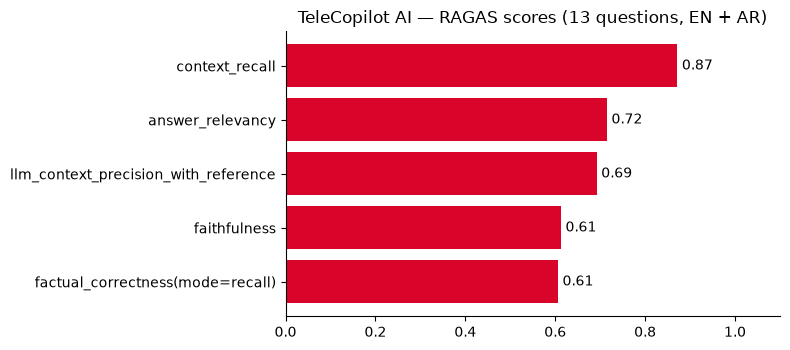

In [7]:
import matplotlib.pyplot as plt
means = scores[metric_cols].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(means.index, means.values, color="#D90429")
for i, v in enumerate(means.values):
    ax.text(v + 0.01, i, f"{v:.2f}", va="center")
ax.set_xlim(0, 1.1)
ax.set_title(f"TeleCopilot AI — RAGAS scores ({len(scores)} questions, EN + AR)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS / "ragas_scores.png", dpi=150)
plt.show()